In [1]:

print("Welcome to Customer Purchase Behaviour Analysis!")
print("My first data analysis notebook is working.")


Welcome to Customer Purchase Behaviour Analysis!
My first data analysis notebook is working.


In [2]:

import pandas as pd

# Load the retail sales dataset
df = pd.read_excel("../data/Online Retail.xlsx")

# Display the first five rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set a consistent chart style
sns.set_theme(style="whitegrid")

# Locate the project data folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "cleaned_retail_sales.csv"

# Load the cleaned retail sales data
df = pd.read_csv(data_path)

# Display the first five rows
display(df.head())

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("Available columns:", df.columns.tolist())


C:\Users\kalai\AppData\Local\Temp\ipykernel_5012\1721178248.py:18: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount,Year,Month,YearMonth,DayOfWeek
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,2010-12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,2010-12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12,Wednesday


Dataset loaded successfully!
Rows and columns: (524878, 13)
Available columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'SalesAmount', 'Year', 'Month', 'YearMonth', 'DayOfWeek']


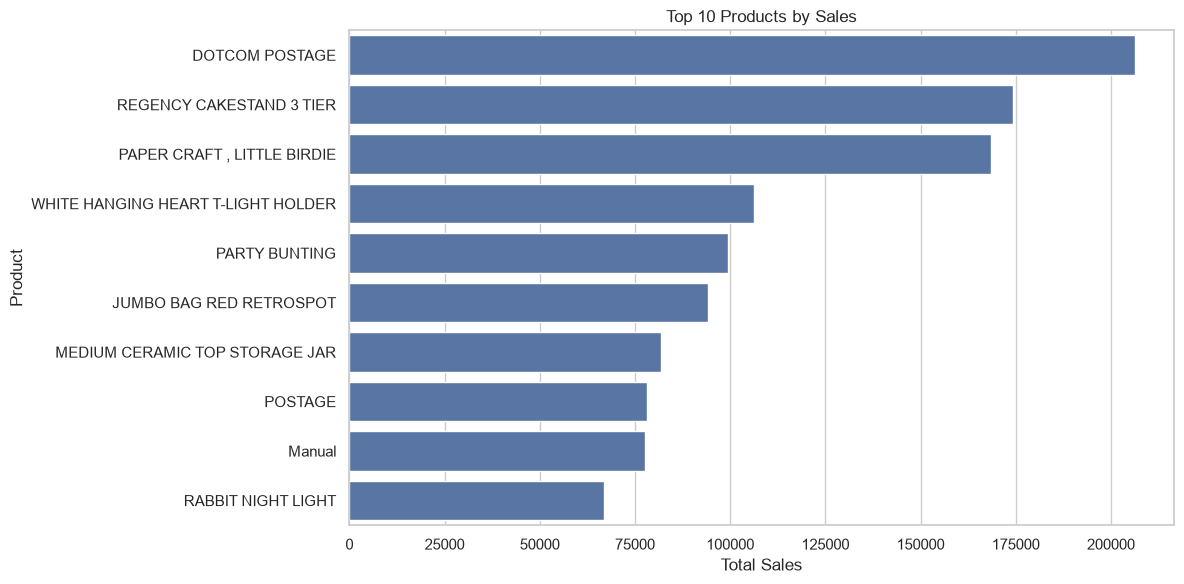

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate sales for each product
top_products = (
    df.groupby("Description")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Create the chart
plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


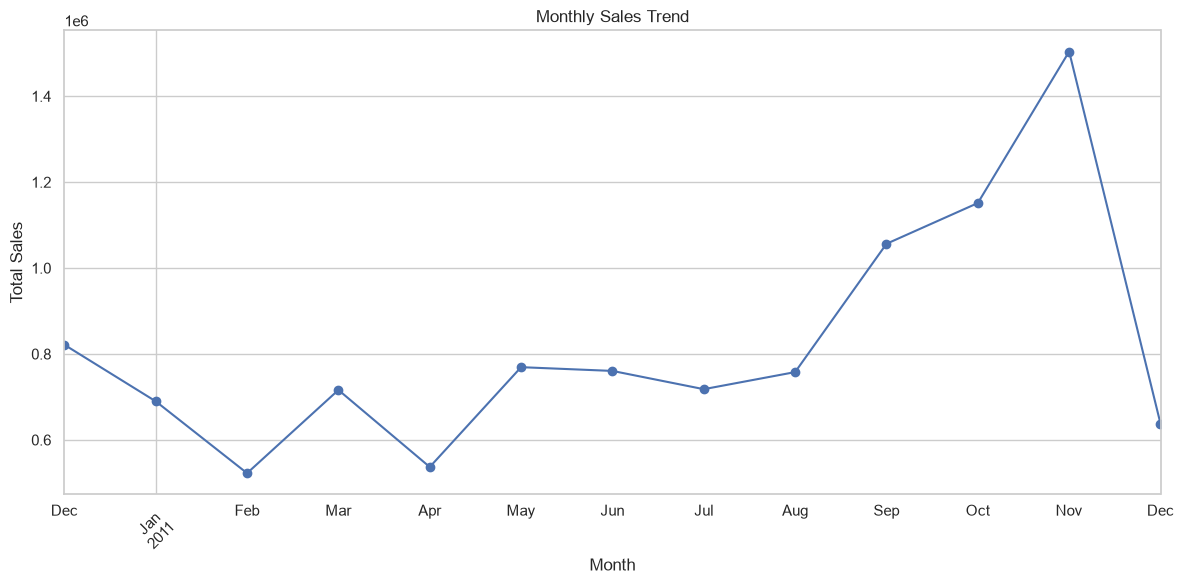

In [5]:

# Convert the invoice date to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Calculate monthly sales
monthly_sales = (
    df.dropna(subset=["InvoiceDate"])
    .set_index("InvoiceDate")["SalesAmount"]
    .resample("MS")
    .sum()
)

# Plot monthly sales
plt.figure(figsize=(12, 6))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

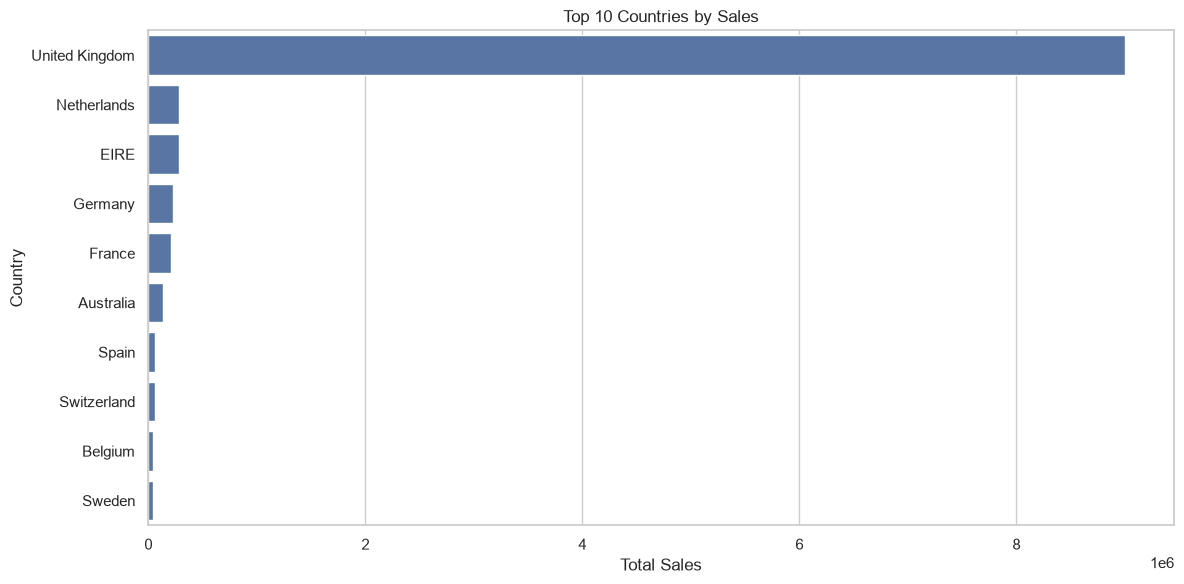

In [6]:

top_countries = (
    df.groupby("Country")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [7]:

from pathlib import Path

segments_path = project_root / "data" / "customer_segments.csv"
segments = pd.read_csv(segments_path)

print("Available columns:", segments.columns.tolist())
display(segments.head())


Available columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'CustomerSegment']


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,CustomerSegment
0,12346,326,1,77183.60,1,1,5,115,Other Customers
1,12347,3,7,4310.00,5,5,5,555,Best Customers
2,12348,76,4,1797.24,2,4,4,244,At-Risk Customers
3,12349,19,1,1757.55,4,1,4,414,New or Promising Customers
4,12350,311,1,334.40,1,1,2,112,Other Customers
